# Meridional transects of mean planetary geostrophic potential vorticity, potential density anomaly and max/min monthly mean MLD

See [Kiss et al 2020](https://doi.org/10.5194/gmd-13-401-2020) Fig 15

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-2/"
nbname = "pPV.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import get_experiment_info, guess_experiment_from_esm_file
from model_agnostic import get_lon_lat_from_catalog, select_variable, patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
import xarray as xr
import cf_xarray as cfxr
import intake
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
from pathlib import Path

xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [5]:
from model_agnostic import patch_dask_workers
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)

http://127.0.0.1:8787/status


In [6]:
def prepare_model_window(
    da_model: xr.DataArray,
    datastore,
    *,
    exptname: str,
    averaging_mode: str = "last_n_years",   # "full_period" / "last_n_years" / "fixed_period"
    averaging_last_n_years: int = 10,
    averaging_start_date: str | None = None,
    averaging_end_date: str | None = None,
    region: dict | None = None,  # e.g. {"xt_ocean": -119.875, "yt_ocean": slice(-90, -15), "st_ocean": slice(None, 1700)}
):
    # --------------------------
    # helpers
    # --------------------------
    dim_alias = {
        "xt_ocean": ("xh", "xt_ocean", "lon", "longitude", "x"),
        "yt_ocean": ("yh", "yt_ocean", "lat", "latitude", "y"),
        "st_ocean": ("z_l", "zl", "st_ocean", "lev", "depth", "z"),
    }

    def _pick_dim(key: str, da: xr.DataArray):
        for d in dim_alias.get(key, (key,)):
            if d in da.dims:
                return d
        return None

    def _apply_region(da: xr.DataArray, region: dict):
        if not region:
            return da

        indexers = {}
        for user_dim, sel in region.items():
            d = _pick_dim(user_dim, da)
            if d is None:
                continue  # region asked for a dim this variable doesn't have

            # Exact point selection (e.g. xt_ocean=-119.875) → use nearest
            if not isinstance(sel, slice) and sel is not None:
                da = da.sel({d: sel}, method="nearest")
            else:
                indexers[d] = sel

        if indexers:
            da = da.sel(indexers)

        return da

    # --------------------------
    # 0) OM3 25km IAF grid quirk: yh not monotonic
    # --------------------------
    if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
        if "yh" in da_model.dims:
            da_model = da_model.sortby("yh")

    # 1) Get lon/lat once from catalog
    lon, lat = get_lon_lat_from_catalog(datastore)

    # Apply the same sort to lon/lat if needed (keeps alignment)
    if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
        if "yh" in lon.dims:
            lon = lon.sortby("yh")
        if "yh" in lat.dims:
            lat = lat.sortby("yh")

    # 2) Optional special-case y-slice (must hit data + coords consistently)
    if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
        if "yh" in da_model.dims:
            da_model = da_model.isel(yh=slice(10, None))
            lon = lon.isel(yh=slice(10, None))
            lat = lat.isel(yh=slice(10, None))
        elif "yq" in da_model.dims:
            da_model = da_model.isel(yq=slice(10, None))
            lon = lon.isel(yq=slice(10, None))
            lat = lat.isel(yq=slice(10, None))

    # 3) Attach CF lon/lat if missing
    try:
        _ = da_model.cf["longitude"]
        _ = da_model.cf["latitude"]
        model_all = da_model
        print("Using existing CF longitude/latitude on da_model.")
    except KeyError:
        model_all = da_model.cf.assign_coords({"longitude": lon, "latitude": lat})
        print("Attached longitude/latitude from catalog grid variables.")

    # 4) Apply region restriction (works across xt_ocean/yt_ocean/st_ocean OR xh/yh/z_l etc.)
    model_all = _apply_region(model_all, region)
    print("model_all dims (after region):", model_all.dims)

    # 5) Calendar normalisation + time window
    if "time" in model_all.dims or "time" in model_all.coords:
        model_all = model_all.convert_calendar("proleptic_gregorian", use_cftime=True)

        t0 = model_all.time.values[0]
        t1 = model_all.time.values[-1]
        print("Full model time range:", t0, "→", t1)

        if averaging_mode == "full_period":
            datestart, datestop = t0, t1

        elif averaging_mode == "last_n_years":
            datestop = t1
            datelist = list(cftime.to_tuple(datestop))
            datelist[0] -= averaging_last_n_years
            datestart = cftime.datetime(*datelist, calendar=datestop.calendar)

        elif averaging_mode == "fixed_period":
            if averaging_start_date is None or averaging_end_date is None:
                raise ValueError("fixed_period requires averaging_start_date and averaging_end_date")
            datestart = xr.cftime_range(
                start=averaging_start_date, periods=1, calendar="proleptic_gregorian"
            )[0]
            datestop = xr.cftime_range(
                start=averaging_end_date, periods=1, calendar="proleptic_gregorian"
            )[0]
        else:
            raise ValueError(f"Unknown averaging_mode: {averaging_mode!r}")

        timerange = slice(datestart, datestop)
        print("Averaging window:", timerange)

        model_window = model_all.cf.sel(time=timerange)
        print("Windowed dims:", model_window.dims)
    else:
        print("No time axis found; skipping time-windowing.")
        model_window = model_all

    return model_all, model_window, lon, lat, datestart, datestop


In [7]:
def load_comparison_data(
    *,
    model_name: str,
    region: dict,
    om2_experiment: str,
    last_n_months: int = 120,
    cm2_potrho_file: str = "/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/",
    cm2_mld_file: str = "/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/",
):
    """
    Return a dict with reference datasets/fields, selecting:
      - OMIP2 (intake-esm) when model_name == ACCESS-OM3
      - CM2 postprocessed files when model_name == ACCESS-CM3
    """
    def _load_one(varname: str, last_n_months: int | None = None) -> xr.DataArray:
        if varname in ("geolon_t", "geolat_t"):
            dd = (
                ds_cat.search(variable=varname)
                .to_dataset_dict(
                    xarray_open_kwargs=dict(
                        decode_timedelta=True,
                        use_cftime=True,
                    ),
                    xarray_combine_by_coords_kwargs=dict(
                        compat="override",
                        coords="minimal",
                        data_vars="minimal",
                    ),
                    progressbar=False,
                )
            )
        else:
            dd = (
                ds_cat.search(variable=varname, frequency="1mon")
                .to_dataset_dict(
                    xarray_open_kwargs=dict(
                        chunks={"time": 1},   # NOT -1
                        decode_timedelta=True,
                        use_cftime=True,
                    ),
                    xarray_combine_by_coords_kwargs=dict(
                        compat="override",
                        coords="minimal",
                        data_vars="minimal",
                    ),
                    progressbar=False,
                )
            )
        key = sorted(dd.keys())[0]
        da = dd[key][varname]
        return da
    
    if model_name == "ACCESS-OM3":
        cat = intake.cat.access_nri
        ds_cat = cat[om2_experiment]

        # IMPORTANT: don't do ds_cat.to_dask() (it has multiple datasets)
        # Load only what we need via search + to_dataset_dict, then pick one.
        pot_rho_0 = _load_one("pot_rho_0", last_n_months=120)
        mld       = _load_one("mld",       last_n_months=120)
        geolat_t = _load_one("geolat_t")
        geolon_t = _load_one("geolon_t")
        ds_ref = xr.Dataset({"pot_rho_0": pot_rho_0, "mld": mld, "geolon_t": geolon_t, "geolat_t": geolat_t})
        ds_ref = ds_ref.assign_coords(
            geolon_t=geolon_t,
            geolat_t=geolat_t,)
        ds_ref = ds_ref.sel(**region)

        if "time" in ds_ref.dims:
            ds_ref = ds_ref.isel(time=slice(-last_n_months, None))

        ds_ref = ds_ref.compute()

        period_ref = (
            ds_ref.time[0].item().strftime("%Y-%m-%d"),
            ds_ref.time[-1].item().strftime("%Y-%m-%d"),
        )

        return dict(
            ref_label=f"OMIP2 ({om2_experiment})",
            ds_ref=ds_ref,
            period_ref=period_ref,
            potrho0_plot_ref=ds_ref["pot_rho_0"].mean("time"),
            mldmin_ref=ds_ref["mld"].min("time"),
            mldmax_ref=ds_ref["mld"].max("time"),
            pPV_plot_ref=(ds_ref["pPV"].mean("time") if "pPV" in ds_ref else None),
        )


    elif model_name == "ACCESS-CM3":
        cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
        last_n_months = 120
    
        # ---- pot_rho_0 (3D monthly) ----
        rho_files_all = sorted(cm2_dir.glob("ocean-3d-pot_rho_0-1-monthly-mean-ym_*.nc"))
        rho_files = rho_files_all[80:100]  # model years 41-50, matching CM3's last decade (6 months per file)

        if not rho_files:
            raise FileNotFoundError("No pot_rho_0 monthly files found")
    
        ds_rho = xr.open_mfdataset(
            rho_files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 12},
            decode_timedelta=True,
            use_cftime=True,
        )
    
        potrho0 = ds_rho["pot_rho_0"].isel(time=slice(None, last_n_months)).sel(**region)
    
        # ---- mld (2D monthly) ----
        mld_files = sorted(cm2_dir.glob("ocean-2d-mld-1-monthly-mean-ym_*.nc"))
        if not mld_files:
            raise FileNotFoundError("No mld monthly files found")
    
        ds_mld = xr.open_mfdataset(
            mld_files[80:100],
            combine="by_coords",
            parallel=True,
            chunks={"time": 12},
            decode_timedelta=True,
            use_cftime=True,
        )
    
        mld = (
            ds_mld["mld"]
            .isel(time=slice(None, last_n_months))
            .sel(xt_ocean=-119.875)
            .sel(yt_ocean=slice(-90, -15))
        )    
        ds_ref = xr.Dataset({"pot_rho_0": potrho0, "mld": mld}).convert_calendar("proleptic_gregorian", use_cftime=True)
        period_ref = (
            str(potrho0.time.values[0]),
            str(potrho0.time.values[-1]),
        )
    
        return dict(
            ref_label="CM2 (cj877 years 41-50, matches CM3 last decade)",
            ds_ref=ds_ref,
            period_ref=period_ref,
            potrho0_plot_ref=potrho0.mean("time"),
            mldmin_ref=mld.min("time"),
            mldmax_ref=mld.max("time"),
            pPV_plot_ref=None,
        )
    else:
        raise ValueError(f"Unknown model_name: {model_name!r}")

# ACCESS OM3 or CM3

### Open the intake-esm datastore

In [8]:
from exptdata_access import get_exptname_from_path
exptname=get_exptname_from_path(esm_file)
print("Experiment name:", exptname)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

Experiment name: MC_8km_jra_ryf-test2-expt-c349f800


### Open required variables

**TODO**: Should be using `rhopot0`, but this is not currently saved

In [9]:
data_frequency = "1mon"

# --- Potential density (rho_pot_0) ---
if model_name == "ACCESS-CM3":
    # CM3 stores yearly files; default chunking would make one ~6 GB chunk per file
    rho_chunks = {"chunks": {"time": 1}}
else:
    rho_chunks = {}
rho = select_variable(
    datastore,
    variable_standard_name="Potential density referenced to surface",
    fallback_variable_names=["rhopot0", "rhopot2"],
    data_frequency=data_frequency,
    **rho_chunks,
)

rho_sigma_offset = 0 if rho.name == "rhopot0" else 8  # rhopot2 is referenced to 2000db, ~8 kg/m3 higher

print("Selected rho variable:", rho.name)
print("rho dims:", rho.dims)


# --- Mixed Layer Depth ---
mld = select_variable(
    datastore,
    variable_standard_name="Ocean Mixed Layer Thickness Defined by Sigma T",
    fallback_variable_names=[
        "mlotst",
        "mld",
        "mixed_layer_depth",
        "mixed_layer_thickness",
    ],
    data_frequency=data_frequency,
)
print("Selected MLD variable:", mld.name)
print("MLD dims:", mld.dims)

CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b66feed0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b622b0b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b622f890>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b62288f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b622e870>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b670e1b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1464b4eb08c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Selected variable via fallback name: rhopot0
Selected rho variable: rhopot0
rho dims: ('time', 'z_l', 'yh', 'xh')
CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


Selected variable via fallback name: mlotst
Selected MLD variable: mlotst
MLD dims: ('time', 'yh', 'xh')


In [10]:
averaging_mode = "last_n_years"   # or "full_period" / "fixed_period"
averaging_last_n_years = 10
averaging_start_date = None
averaging_end_date   = None

### Only keep last 10 years of data in the region of interest

In [11]:
region = {
    "xt_ocean": -119.875,
    "yt_ocean": slice(-90, -15),
    "st_ocean": slice(None, 1700),
}

rho_all, rho_window, lon, lat, datestart, datestop = prepare_model_window(
    rho, datastore,
    exptname=exptname,
    averaging_mode=averaging_mode,
    averaging_last_n_years=averaging_last_n_years,
    averaging_start_date=averaging_start_date,
    averaging_end_date=averaging_end_date,
    region=region,
)

mld_all, mld_window, lon, lat, datestart, datestop = prepare_model_window(
    mld, datastore,
    exptname=exptname,
    averaging_mode=averaging_mode,
    averaging_last_n_years=averaging_last_n_years,
    averaging_start_date=averaging_start_date,
    averaging_end_date=averaging_end_date,
    region=region,
)

Using existing CF longitude/latitude on da_model.
model_all dims (after region): ('time', 'z_l', 'yh')
Full model time range: 1900-01-16 12:00:00 → 1909-12-16 12:00:00
Averaging window: slice(cftime.datetime(1899, 12, 16, 12, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.DatetimeProlepticGregorian(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True), None)
Windowed dims: ('time', 'z_l', 'yh')


Using existing CF longitude/latitude on da_model.
model_all dims (after region): ('time', 'yh')
Full model time range: 1900-01-16 12:00:00 → 1909-12-16 12:00:00
Averaging window: slice(cftime.datetime(1899, 12, 16, 12, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.DatetimeProlepticGregorian(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True), None)
Windowed dims: ('time', 'yh')


### Calculate the planetary potential vorticity
Constants below are as used in MOM6 by default

**TODO**: Should we use saved `Coriolis` diagnostic here? It's on q-points so would have to be interpolated.

In [12]:
lat = rho_window.coords.get("geolat", rho["yh"])

In [13]:
g = 9.80
rho0  = 1040.0
omega  = 7.2921e-5
coriolis = 2.0 * omega * np.sin(np.deg2rad(lat))

dpotrho2dz_om3 = rho_window.differentiate(coord="z_l")

pPV_om3 = -coriolis * g / rho0 * dpotrho2dz_om3

In [14]:
pPV_om3_w = pPV_om3.sortby("time").isel(time=slice(-120, None))
pPV_om3_w = pPV_om3_w.chunk({"time": 1})
pPV_plot_om3 = pPV_om3_w.mean("time").compute()

In [15]:
pPV_plot_om3 = pPV_om3.mean("time").compute()
potrho2_plot_om3 = rho_window.mean("time").compute()
mldmin_om3 = mld_window.min("time").compute()
mldmax_om3 = mld_window.max("time").compute()

# Open the intake-esm datastore

### Only keep last 10 years of data in the region of interest

In [16]:
if model_name == "ACCESS-OM3":
    experiment = "025deg_jra55_iaf_omip2_cycle6"
elif model_name == "ACCESS-CM3":
    experiment = "cj877"
    
ref = load_comparison_data(
    model_name=model_name,
    region=region,
    om2_experiment=experiment,
    last_n_months=120,
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(u

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:106: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(url, **xarray_open_kwargs)


### Calculate the planetary potential vorticity

Constants below are as used in MOM5 by default

In [17]:
g = 9.80
rho0  = 1035.0
omega  = 7.292e-5
#lat = ref["ds_ref"]["geolat_t"] 
lat = ref["ds_ref"]["yt_ocean"] 
coriolis = 2.0 * omega * np.sin(np.deg2rad(lat))

dpotrho0dz_om2 = ref["ds_ref"]["pot_rho_0"].differentiate(coord="st_ocean")

pPV_om2 = -coriolis * g / rho0 * dpotrho0dz_om2

# Plot

### Compute OM2 quantities

In [18]:
pPV_plot_om2 = pPV_om2.mean("time")
potrho0_plot_om2 = ref["ds_ref"]["pot_rho_0"].mean("time")
mldmin_om2 = ref["ds_ref"]["mld"].min("time")
mldmax_om2 = ref["ds_ref"]["mld"].max("time")

### Create plot

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-2/mkmd/pPV_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-2/mkmd/pPV.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-2/mkmd/pPV.md successfully.


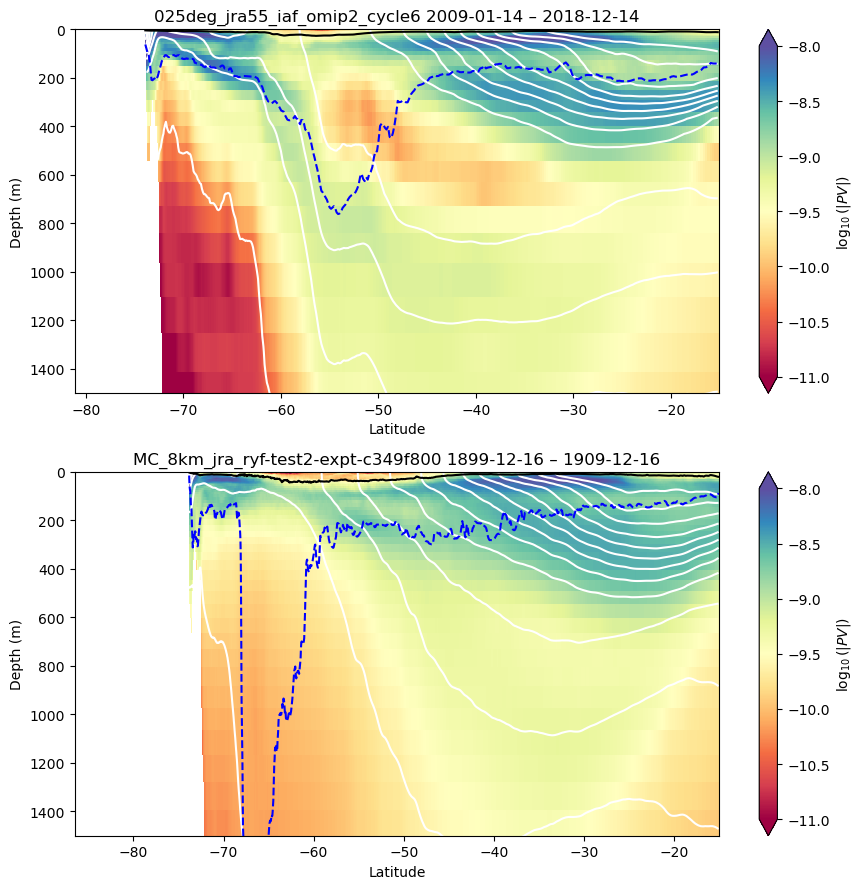

In [19]:
fig, axs = plt.subplots(2, 1, figsize=(9, 9))

# ACCESS-OM2
xr.ufuncs.log10(abs(pPV_plot_om2)).plot(
    ax=axs[0],
    x="yt_ocean",
    cmap="Spectral",
    vmin=-11,
    vmax=-8,
    cbar_kwargs={"label": "$\log_{10}(|PV|)$"},
)
potrho0_plot_om2.plot.contour(
    ax=axs[0],
    levels=np.arange(1024.75, 1030, 0.25),
    colors="w"
)
mldmin_om2.plot(ax=axs[0], color="k")
mldmax_om2.plot(ax=axs[0], color="b", linestyle="--")

axs[0].set_ylim(1500, 0)
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Depth (m)")
axs[0].set_title(f"{experiment} "
                f"{ref['period_ref'][0]} – {ref['period_ref'][1]}")

# ACCESS-OM3
xr.ufuncs.log10(abs(pPV_plot_om3)).plot(
    ax=axs[1],
    x="yh",
    cmap="Spectral",
    vmin=-11,
    vmax=-8,
    cbar_kwargs={"label": "$\log_{10}(|PV|)$"},
)
potrho2_plot_om3.plot.contour(
    ax=axs[1],
    levels=np.arange(1024.75, 1030, 0.25)+rho_sigma_offset,
    colors="w"
)
mldmin_om3.plot(ax=axs[1], color="k")
mldmax_om3.plot(ax=axs[1], color="b", linestyle="--")

axs[1].set_ylim(1500, 0)
axs[1].set_xlabel("Latitude")
axs[1].set_ylabel("Depth (m)")
axs[1].set_title(f"{exptname} " 
                f"{datestart.strftime('%Y-%m-%d')} – {datestop.strftime('%Y-%m-%d')}")

plt.tight_layout()
mkmd.savefig(fig, "Planetary Potential Vorticity", "Meridional transects of mean planetary geostrophic potential vorticity, potential density anomaly, and max/min monthly mean MLD. [GitHub issue: Planetary geostrophic potential vorticity / SAMW transects](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/14)")

In [20]:
client.close()